In [23]:
import os
from typing import List, Union, Optional, Dict
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
from pathlib import Path
import matplotlib.pyplot as plt
import re


def _csv_to_points_gdf(
    csv_path: str,
    lon_col: str = "lon",
    lat_col: str = "lat",
    csv_crs: str = "EPSG:4326",
) -> gpd.GeoDataFrame:
    df = pd.read_csv(csv_path)
    if lon_col not in df.columns or lat_col not in df.columns:
        raise ValueError(f"{csv_path} 缺少列: '{lon_col}' / '{lat_col}'")
    gdf = gpd.GeoDataFrame(
        df,
        geometry=[Point(xy) for xy in zip(df[lon_col], df[lat_col])],
        crs=csv_crs
    )
    return gdf

def _add_north_arrow(ax, size: float = 0.08, pad: float = 0.03):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    dx, dy = x1 - x0, y1 - y0
    x = x1 - dx * pad
    y = y0 + dy * pad        # 锚点放在下方更自然
    L = dy * size
    ax.annotate(
        "", 
        xy=(x, y + L),       # 改成向上箭头
        xytext=(x, y),
        arrowprops=dict(arrowstyle="simple", linewidth=1.1, color="black", facecolor="black")
    )
    ax.text(x, y + L + dy * 0.01, "N", ha="center", va="bottom", fontsize=10, weight="bold")

def overlay_csv_points_on_shp(
    shp_path: str,
    csv_paths: Union[str, List[str]],
    lon_col: str = "lon",
    lat_col: str = "lat",
    csv_crs: str = "EPSG:4326",
    colors: Optional[List[str]] = None,
    labels: Optional[List[str]] = None,
    out_path: Optional[str] = None,
    figsize=(7, 7),
    dpi: int = 300,
    point_size: float = 6.0,
    alpha: float = 0.9,
    edge_color: str = "black",
    edge_lw: float = 0.6,
    facecolor: str = "none",
    tight: bool = True,
):
    """
    将一个或多个 CSV 点(经纬度)叠加到一个 shapefile 上:
    - 自动将点投影到 shapefile 的 CRS
    - 可指定颜色/图例
    - 可保存图片，也可只返回对象

    返回:
        base_gdf: 底图 GeoDataFrame
        points_gdfs: List[GeoDataFrame] (与 csv_paths 一一对应，已转到底图 CRS)
        fig, ax: matplotlib 图对象
    """
    # 规范化输入
    if isinstance(csv_paths, str):
        csv_paths = [csv_paths]
    n = len(csv_paths)

    base_gdf = gpd.read_file(shp_path)
    if base_gdf.empty:
        raise ValueError("Shapefile 为空")
    base_crs = base_gdf.crs

    # 颜色与图例
    if colors is None:
        # 给多个图层默认配色
        default = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd", "#ff7f0e",
                   "#8c564b", "#17becf", "#7f7f7f", "#bcbd22", "#e377c2"]
        colors = [default[i % len(default)] for i in range(n)]
    if labels is None:
        labels = [os.path.splitext(os.path.basename(p))[0] for p in csv_paths]
    if len(colors) != n or len(labels) != n:
        raise ValueError("colors / labels 长度需要与 csv_paths 一致")

    # 读入并投影点
    points_gdfs: List[gpd.GeoDataFrame] = []
    for p in csv_paths:
        gdf_pts = _csv_to_points_gdf(p, lon_col, lat_col, csv_crs)
        if base_crs is not None and gdf_pts.crs != base_crs:
            gdf_pts = gdf_pts.to_crs(base_crs)
        points_gdfs.append(gdf_pts)

    # 画图
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    base_gdf.plot(ax=ax, edgecolor=edge_color, facecolor=facecolor, linewidth=edge_lw)

    handles = []
    for gdf_pts, color, label in zip(points_gdfs, colors, labels):
        if not gdf_pts.empty:
            g = gdf_pts.plot(ax=ax, markersize=point_size, color=color, alpha=alpha, label=label)
            handles.append(g)

    ax.set_xlim(*base_gdf.total_bounds[[0, 2]])
    ax.set_ylim(*base_gdf.total_bounds[[1, 3]])
    ax.set_axis_off()
    _add_north_arrow(ax)

    if n > 1:
        ax.legend(frameon=False, loc="lower left")

    if tight:
        plt.tight_layout()

    if out_path:
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.05)

    return base_gdf, points_gdfs, fig, ax

## 这个现在被舍弃了 因为这个调用函数写的太大了
其实就是调用上面的函数 但是我现在要用一些新的方法直接去读文件夹所以不能直接这样调用 用下面的那个新的


In [24]:
overlay_csv_points_on_shp(
    shp_path="/Users/a1-6/Self_program/underground_water/boundary/Poyang_Lakes1.shp",

    
    #2019-2020
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20191106011604_06130506_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20191119123516_08190502_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20191204235205_10550506_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20200131210410_05520606_007_01_Rule1_full.csv",  
    # ],

    #2020-2021
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20201103075511_06130906_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20201231050721_01101006_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20210117161809_03771002_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20210129034327_05521006_007_01_Rule1_full.csv",  
    # ],
    
    #2021-2022
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211115015401_08191302_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211130131051_10551306_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211218002145_13221302_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211229114654_01101406_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20220102113835_01711406_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20220111230607_03161402_007_01_Rule1_full.csv",
    # ],
    
    #2022-2023
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20221128195015_10551706_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20221212070923_12611702_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20230110054523_03161802_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20230129165410_06131806_007_01_Rule1_full.csv",
    # ],
    #2022 12月
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20221212070923_12611702_007_01_Rule1_full.csv",
    # ], 
    
    #2023-2024
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20231127022828_10552106_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20231226010431_01102206_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20240112121516_03772202_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20240123234022_05522206_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20240127233201_06132206_007_01_Rule1_full.csv",        
    # ],


    #GEDI
    # csv_paths=["/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022338025411_O22522_02_T03572_02_003_02_V002_clippoints.csv"
    # ],
    # GEDI2021-2022
    # csv_paths = [
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021323090951_O16633_02_T07030_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021327073819_O16694_02_T03878_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021331060638_O16755_02_T09264_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021335043442_O16816_02_T07841_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021362174130_O17243_02_T04842_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022001160539_O17304_02_T02455_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022016181355_O17538_03_T06974_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022020163856_O17599_03_T07280_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022024150347_O17660_03_T00318_02_003_02_V002_subsetted_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022028132825_O17721_03_T07739_02_003_02_V002_clippoints.csv",
    # ],
    # csv_paths = [
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021323090951_O16633_02_T07030_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021327073819_O16694_02_T03878_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021331060638_O16755_02_T09264_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021335043442_O16816_02_T07841_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2021362174130_O17243_02_T04842_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022001160539_O17304_02_T02455_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022016181355_O17538_03_T06974_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022020163856_O17599_03_T07280_02_003_02_V002_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022024150347_O17660_03_T00318_02_003_02_V002_subsetted_clippoints.csv",
    #     "/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI02_A_2022028132825_O17721_03_T07739_02_003_02_V002_clippoints.csv",
    # ],
    # 你的目标文件夹路径
    
    folder = Path("/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI_2022-2023")    
    csv_paths = sorted([str(p) for p in folder.glob("*.csv")])
    
    
   
    # labels=["20191106", "20191119", "20191204","20200131"], 
    # labels=["20211115", "2021113", "20211218","20211229","20220102","20220111"], 
    # labels=["20221128", "20221212", "20230110","20230129"], 
    # labels=["20221212"], 
    # labels=["20231127", "20231226", "20240112","20240123","20240127"],
    # labels = ["2022307", "2022311", "2022315","2022322","2022326", "2022338", "2022342","2022353","2022357","2023007", "2023011","2023018","2023022"]
    def label_from_name(p: str) -> str:
        m = re.search(r"_A_(\d{7})_", p)  # 抓 7 位的 YYYYDOY
        return m.group(1)[-3:] if m else Path(p).stem  # 仅用 DOY，或用整段 m.group(1)
    
    labels = [label_from_name(p) for p in csv_paths]
    # 2019-2020
    # out_path="/Users/a1-6/Self_program/underground_water/2019_2020_11_12_1.png"
    #2020-2021
    # out_path="/Users/a1-6/Self_program/underground_water/2020_2021_11_12_1.png"
    # out_path="/Users/a1-6/Self_program/underground_water/2022_2023_11_12_1.png"
    # 2022 12
    # out_path="/Users/a1-6/Self_program/underground_water/2022_12.png"
    # out_path="/Users/a1-6/Self_program/underground_water/2023_2024_11_12_1.png"
    # out_path="/Users/a1-6/Self_program/underground_water/GEDI/image/2020_2021_11_12_1.png"
    out_path="/Users/a1-6/Self_program/underground_water/GEDI/image/2022_2023_11_12_1.png"
    
)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1506936967.py, line 83)

/var/folders/g4/7p7jhdhs7n13ct9qwch888v80000gn/T/ipykernel_16154/2784022977.py:33: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(


(   OBJECTID  Join_Count  TARGET_FID  Edit_Seq GEP_Check   Area_54009  \
 0         1           2        1961         2      None  3178.945023   
 
    Region_Typ Region_Nam Name  Lake_ID  v1_Lake_ID  v11_LakeID  ORIG_FID  \
 0           5       东部平原  鄱阳湖        2           2           2         0   
 
    Shape_Leng   Shape_Area           c         y  \
 0   25.672853  3071.252772  116.278258  29.15302   
 
                                             geometry  
 0  POLYGON Z ((116.19636 29.70962 0, 116.19582 29...  ,
 [          beam        lat         lon  dem_h  h_te_interp    h_te_mean  \
  0     BEAM1011  29.412907  116.002577    NaN  4783.360400  4783.360400   
  1     BEAM1011  29.413284  116.002978    NaN  4783.161600  4783.161600   
  2     BEAM1011  29.413662  116.003380    NaN  4783.649000  4783.649000   
  3     BEAM1011  29.414039  116.003781    NaN  4783.113000  4783.113000   
  4     BEAM1011  29.414416  116.004182    NaN  4783.173000  4783.173000   
  ...        ...   

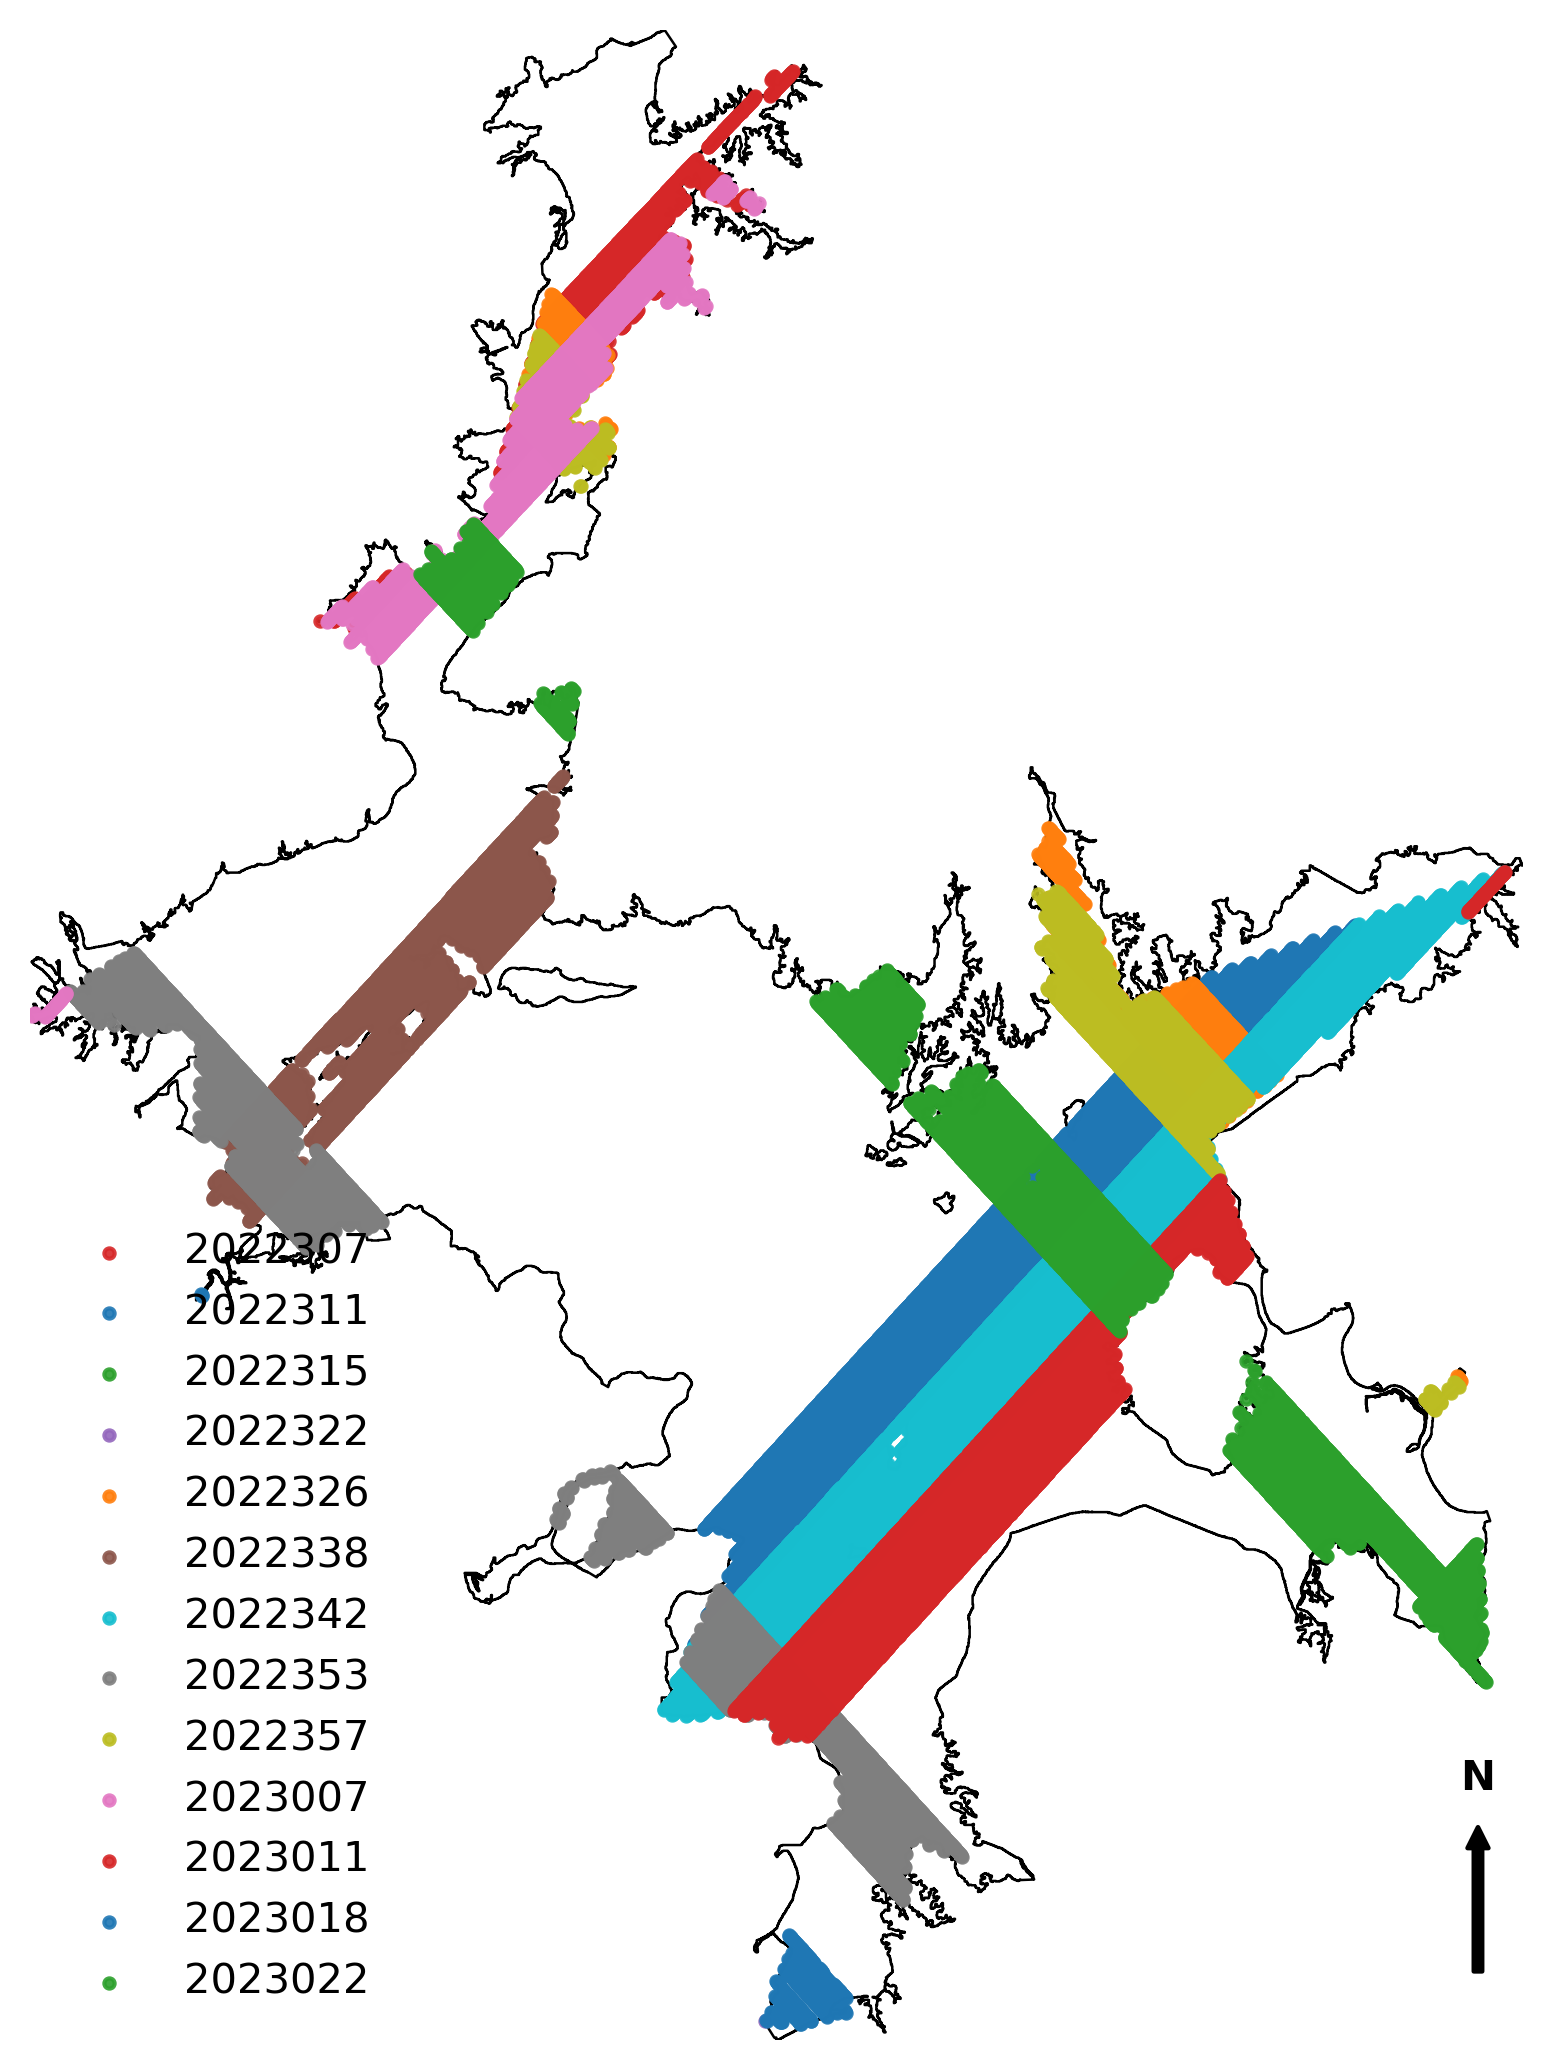

In [27]:
shp_path = "/Users/a1-6/Self_program/underground_water/boundary/Poyang_Lakes1.shp"

folder = Path("/Users/a1-6/Self_program/underground_water/GEDI/clip_points_out/GEDI_2022-2023")
csv_paths = sorted(str(p) for p in folder.glob("*.csv"))



def label_from_name(p: str) -> str:
    name = Path(p).name
    # 取 _A_ 后的前 7 位（YYYYDOY），后面可以继续有数字，直到出现下划线
    m = re.search(r"_A_(\d{7})(?=\d*_)", name)   # 推荐：用前瞻保证后面最终有一个下划线
    # 或者更宽松一点：m = re.search(r"_A_(\d{7})", name)
    return m.group(1) if m else name   

labels = [label_from_name(p) for p in csv_paths]

out_path = "/Users/a1-6/Self_program/underground_water/GEDI/image/2022_2023_11_12_1.png"

overlay_csv_points_on_shp(
    shp_path=shp_path,
    csv_paths=csv_paths,
    labels=labels,
    out_path=out_path,
)